# Lab 1: Vacuum Cleaner Agent (2D Continuous - 28x28 with Visualizations)
This notebook scales the grid to 28x28 (MNIST dimensions), increases the step count so the agents can actually cover the larger area, and changes the scoring metric to a much more intuitive **Percentage of Dirt Removed (0% to 100%)**.

## mohammad ali najafzadeh
### with gemeni 3.1 pro

In [1]:
import sys, numpy as np, matplotlib, matplotlib.pyplot as plt
from datetime import datetime
from zoneinfo import ZoneInfo
import pandas as pd
print("Python Version:")
print(sys.version, sys.executable)
print(np.__version__, matplotlib.__version__)
print("+03:30 Time of run:", datetime.now(ZoneInfo("Asia/Tehran")).strftime("%Y-%m-%d %H:%M:%S"))
print("""
Ran by Mohammad Ali Najafzadeh

Group Info
Manager: Mohammad Ali Najafzadeh
________________________________

Group Members:
Mohammad Ali Najafzadeh
Amir Hossein Hasani
Reza Dehghani
Amir Hossein Noruzi
""")

GRID_SIZE = 28  # 28x28 grid = 784 rooms
STEPS = 1500    # Increased steps so the agent has time to explore 784 rooms
RUNS = 50      # Number of statistical runs

Python Version:
3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)] c:\Users\lnt-ltp\anaconda3\python.exe
2.4.6 3.11.0
+03:30 Time of run: 2026-10-23 22:28:43

Ran by Mohammad Ali Najafzadeh

Group Info
Manager: Mohammad Ali Najafzadeh
________________________________

Group Members:
Mohammad Ali Najafzadeh
Amir Hossein Hasani
Reza Dehghani
Amir Hossein Noruzi



## The Core Simulation Function
Scoring is now calculated by comparing the sum of dirt at the start to the sum of dirt at the end. We also added a tracking system to capture the agent's path for plotting.

In [2]:
def simulate(agent, seed, return_visuals=False):
    rng = np.random.default_rng(seed)
    dirt = rng.random((GRID_SIZE, GRID_SIZE))
    initial_dirt_sum = dirt.sum()
    
    if return_visuals:
        initial_dirt_grid = dirt.copy()
        traj_r, traj_c = [0], [0]
        
    known_clean = np.zeros((GRID_SIZE, GRID_SIZE), dtype=bool)
    row, col, direction = 0, 0, 1

    for step in range(STEPS):
        # 1. Perception
        if dirt[row, col] == 0.0:
            known_clean[row, col] = True

        # 2. Action Selection
        if agent == "random":
            action = rng.choice(["Up", "Down", "Left", "Right", "Suck"])
        elif dirt[row, col] > 0.0:
            action = "Suck"
        elif agent == "reflex":
            action = rng.choice(["Up", "Down", "Left", "Right"])
        elif known_clean.all():
            action = "NoOp"
        else:
            # 2D Lawnmower policy
            if direction == 1 and col == GRID_SIZE - 1:
                action = "Down"
                direction = -1
            elif direction == -1 and col == 0:
                action = "Down"
                direction = 1
            else:
                action = "Right" if direction == 1 else "Left"

        # 3. Physics / Apply Action
        if action == "Suck":
            dirt[row, col] = 0.0
        elif action == "Up":
            row = max(row - 1, 0)
        elif action == "Down":
            row = min(row + 1, GRID_SIZE - 1)
        elif action == "Left":
            col = max(col - 1, 0)
        elif action == "Right":
            col = min(col + 1, GRID_SIZE - 1)

        if return_visuals:
            traj_r.append(row)
            traj_c.append(col)

    # Calculate score as a Percentage of Dirt Removed
    final_dirt_sum = dirt.sum()
    percent_cleaned = ((initial_dirt_sum - final_dirt_sum) / initial_dirt_sum) * 100
    
    if return_visuals:
        return percent_cleaned, initial_dirt_grid, dirt.copy(), traj_r, traj_c
    return percent_cleaned

## Visualizing the Agents' Performance
Let's look at the starting dirt layout, the final layout, and the exact path each agent took.

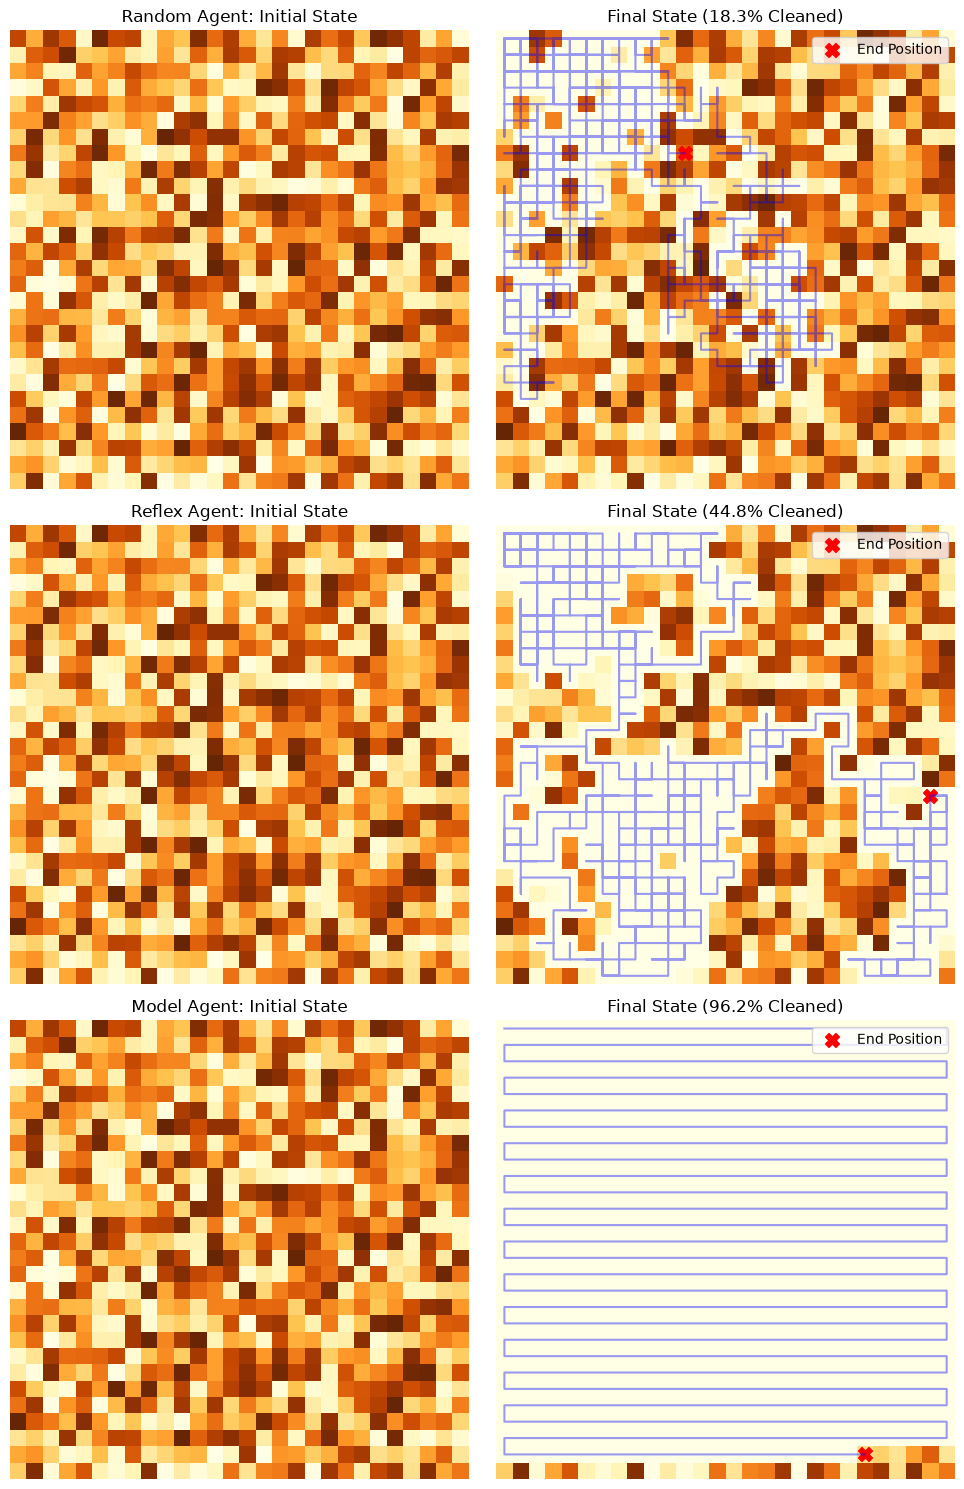

In [3]:
fig, axes = plt.subplots(3, 2, figsize=(10, 15))
agents = ["random", "reflex", "model"]

for i, agent in enumerate(agents):
    score, init_grid, final_grid, traj_r, traj_c = simulate(agent, seed=42, return_visuals=True)
    
    # Plot Initial State
    ax_init = axes[i, 0]
    ax_init.imshow(init_grid, cmap='YlOrBr', vmin=0, vmax=1)
    ax_init.set_title(f"{agent.capitalize()} Agent: Initial State")
    ax_init.axis('off')
    
    # Plot Final State & Trajectory
    ax_final = axes[i, 1]
    ax_final.imshow(final_grid, cmap='YlOrBr', vmin=0, vmax=1)
    # Draw the path taken (x=col, y=row)
    ax_final.plot(traj_c, traj_r, color='blue', alpha=0.4, linewidth=1.5)
    # Mark where the agent ended up
    ax_final.scatter(traj_c[-1], traj_r[-1], color='red', marker='X', s=100, label='End Position')
    
    ax_final.set_title(f"Final State ({score:.1f}% Cleaned)")
    ax_final.axis('off')
    ax_final.legend(loc='upper right')

plt.tight_layout()
plt.show()

## Statistical Aggregation
Running the agents 50 times to get stable averages of their cleaning percentage.

In [4]:
rows = []
for agent in ["random", "reflex", "model"]:
    for seed in range(RUNS):
        rows.append({"agent": agent, "score_percent": simulate(agent, seed)})

df = pd.DataFrame(rows)
summary = df.groupby("agent")["score_percent"].agg(["mean", "std"]).round(1)
print(summary)

        mean  std
agent            
model   95.7  0.4
random  19.4  2.7
reflex  40.0  6.6


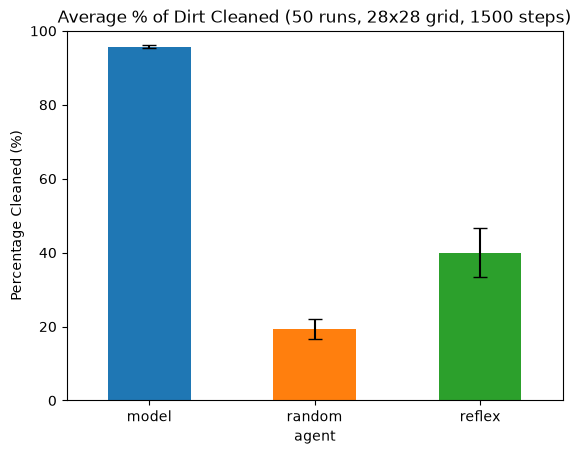

In [5]:
summary["mean"].plot(kind="bar", yerr=summary["std"], capsize=5, color=['#1f77b4', '#ff7f0e', '#2ca02c'])
plt.title(f"Average % of Dirt Cleaned ({RUNS} runs, {GRID_SIZE}x{GRID_SIZE} grid, {STEPS} steps)")
plt.ylabel("Percentage Cleaned (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()